What is Probability?
Probability is the chance of an event happening. Its value ranges from 0 to 1.
Probability = Favourable Outcomes / Total Outcomes

Ex: total students 500 , 309 passed the final exam.
    p=309/500
     =0.618
     =61.8%

Ex 1: Probability that a student passes the final examination
Total students = 500
Students who passed = 309
Let A be the event that a student passes.
P(A)=309/500
P(A)=61.8%
There is a 61.8% probability of selecting a student who passed the final examination from the dataset.

Ex 2: Probability that a student studies more than 10 hours per week
Total students = 500
Students studying more than 10 hours per week = 327
Let B be the event that a student studies more than 10 hours per week.
P(B)=327/500
P(B)=65.4%
Approximately 65.4% of the students in the dataset studied more than 10 hours per week.

Ex 3: Probability that a student studies more than 10 hours and has attendance above 80%
Total students = 500
Students satisfying both conditions = 110
Let C be the event that a student studies more than 10 hours per week and has attendance above 80%.
P(C)=110/500
P(C)=22%
There is a 22% probability of selecting a student who satisfies both the study-hours and attendance conditions.

2 Types of Events
Probability can be calculated using different approaches.

i) Empirical Probability
Empirical probability is calculated using actual observations or collected data. It tells us how frequently an event occurred in the observed dataset.
Ex. Finding the probability that a student passes the final examination.
Total students = 500
Students who passed = 309
P(A)=Number of times event A occurred/Total observations

ii)Theoretical Probability
Theoretical probability is calculated using a mathematical model based on possible outcomes and their assumed likelihoods, rather than observed frequencies.
Ex. Suppose we use a simplified model in which the two possible examination outcomes, Pass and Fail, are equally likely.
S={Pass, Fail}
There are two possible outcomes, and under this model, each outcome is assumed to have an equal chance of occurring
P(A)=Favourable outcomes/Total equally likely outcomes

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import comb
from matplotlib.patches import Circle

df = pd.read_csv(r"C:\Users\KRISHNA\Downloads\student_performance_500.csv")

print("Dataset Shape:", df.shape)

print(df.head())
print(df.isnull().sum())

n = len(df)

Dataset Shape: (500, 5)
   study_hours  attendance group_discussion  previous_test_score  \
0            7          81               No                   22   
1           20          94               No                   56   
2           29          65               No                   62   
3           15          74              Yes                   59   
4           11          89              Yes                   74   

  final_exam_pass  
0            Fail  
1            Fail  
2            Pass  
3            Pass  
4            Pass  
study_hours            0
attendance             0
group_discussion       0
previous_test_score    0
final_exam_pass        0
dtype: int64


In [21]:
n = len(df)

passes = (df["final_exam_pass"] == "Pass").sum()
fails = (df["final_exam_pass"] == "Fail").sum()

print("Total Students:", n)
print("Passed:", passes)
print("Failed:", fails)

print("P(Pass) =", passes / n)
print("P(Fail) =", fails / n)

A = df["study_hours"] > 10
B = df["attendance"] > 80

print("P(Study > 10 hours):", A.mean())
print("P(Attendance > 80%):", B.mean())
print("P(Both conditions):", (A & B).mean())

Total Students: 500
Passed: 309
Failed: 191
P(Pass) = 0.618
P(Fail) = 0.382
P(Study > 10 hours): 0.654
P(Attendance > 80%): 0.342
P(Both conditions): 0.22


In [22]:
p = passes / n
distribution = []
for x in range(4):
    prob = comb(3, x) * p**x * (1-p)**(3-x)
    distribution.append([x, prob])

result = pd.DataFrame(distribution,columns=["Number of Students Passing", "Probability"])
print(result)
print("Mean =", 3 * p)
print("Variance =", 3 * p * (1-p))

   Number of Students Passing  Probability
0                           0     0.055743
1                           1     0.270543
2                           2     0.437685
3                           3     0.236029
Mean = 1.854
Variance = 0.7082280000000001


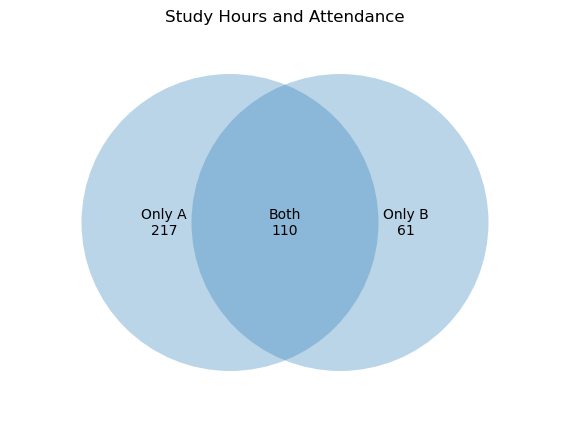

In [23]:
A = df["study_hours"] > 10
B = df["attendance"] > 80

only_A = (A & ~B).sum()
only_B = (~A & B).sum()
both = (A & B).sum()

fig, ax = plt.subplots(figsize=(8, 5))

circle1 = Circle((0.4, 0.5), 0.27, alpha=0.3)
circle2 = Circle((0.6, 0.5), 0.27, alpha=0.3)

ax.add_patch(circle1)
ax.add_patch(circle2)

ax.text(0.28, 0.5, f"Only A\n{only_A}", ha="center", va="center")
ax.text(0.72, 0.5, f"Only B\n{only_B}", ha="center", va="center")
ax.text(0.5, 0.5, f"Both\n{both}", ha="center", va="center")

ax.set_title("Study Hours and Attendance")
ax.set_xlim(0, 1)
ax.set_ylim(0.15, 0.85)
ax.set_aspect("equal")
ax.axis("off")

plt.show()

In [17]:
table = pd.crosstab(df["group_discussion"],  df["final_exam_pass"])
print(table)

final_exam_pass   Fail  Pass
group_discussion            
No                  80    99
Yes                111   210


In [18]:
joint = table.loc["Yes", "Pass"] / n
marginal = passes / n
conditional = (table.loc["Yes", "Pass"] / table.loc["Yes"].sum())
print("Joint Probability:", joint)
print("Marginal Probability:", marginal)
print("Conditional Probability:", conditional)

Joint Probability: 0.42
Marginal Probability: 0.618
Conditional Probability: 0.6542056074766355


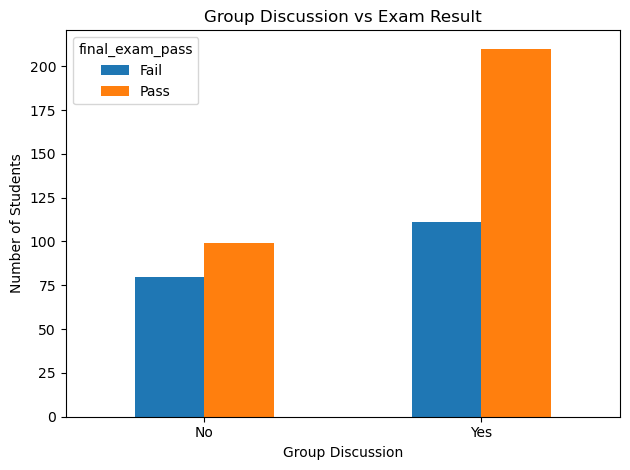

In [49]:
table.plot(kind="bar")
plt.title("Group Discussion vs Exam Result")
plt.xlabel("Group Discussion")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

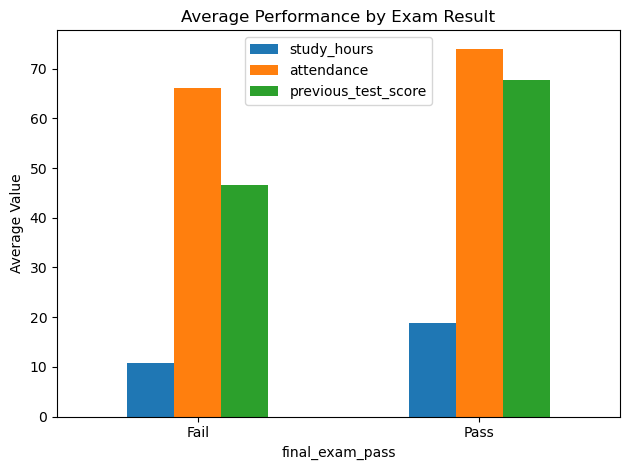

In [19]:

df.groupby("final_exam_pass")[ ["study_hours", "attendance", "previous_test_score"]].mean().plot(kind="bar")

plt.title("Average Performance by Exam Result")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
P_H_given_Pass = 0.70
P_H_given_Fail = 0.40
P_H = 0.60

P_Pass = (P_H-P_H_given_Fail)/( P_H_given_Pass-P_H_given_Fail)
answer = (P_H_given_Pass*P_Pass)/P_H

print("P(Pass) =",P_Pass)
print("P(Pass | High Attendance) =",answer)
print("Percentage =", answer * 100,"%")

P(Pass) = 0.6666666666666666
P(Pass | High Attendance) = 0.7777777777777777
Percentage = 77.77777777777777 %
